# Final US-China Relative Orientation Index: Core and Experimental Specifications

This notebook implements the revised production architecture after the dashboard review.

## Production interpretation

- **Positive** values indicate greater orientation toward the United States.
- **Negative** values indicate greater orientation toward China.
- **Zero** indicates no net directional advantage. The underlying status must still distinguish no ties from offsetting ties.

## Index architecture

The **official core index** uses three completed pillars:

1. security;
2. diplomatic; and
3. economic.

The ICT-goods trade measure is retained as an **experimental technology feature**. It remains available for maps, profiles and user scenarios, but it does not enter the official core benchmark because the accessible TiVA data discount each exporter's foreign value added without reallocating that value by country of origin.

The notebook also:

- fixes the all-missing weighted-row bug;
- applies canonical entity and historical-year eligibility;
- compares complete and available-pillar core scores;
- audits the effect of experimental technology;
- tests whether security no-ties zeros should remain neutral or become unavailable evidence; and
- prepares the continuous index for the later Jenks classification workstream.


## 1. Configuration and production builder

In [1]:
from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def find_repository_root(start=None):
    current = Path.cwd() if start is None else Path(start).resolve()

    for candidate in [current, *current.parents]:
        if (
            (candidate / "src" / "data" / "build_closeness_index.py").exists()
            and (candidate / "data" / "processed").exists()
        ):
            return candidate

    raise FileNotFoundError(
        "Could not locate the repository root containing "
        "'src/data/build_closeness_index.py' and 'data/processed/'."
    )


ROOT = find_repository_root()

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data.build_closeness_index import (
    CORE_PILLARS,
    EXPERIMENTAL_PILLARS,
    build_panel,
    weighted_index,
)

INPUT_DIR = ROOT / "data" / "processed"
MASTER_PATH = (
    ROOT
    / "outputs"
    / "tables"
    / "relations_condition"
    / "relationship_condition_country_master.csv"
)
OUTPUT_DIR = ROOT / "outputs" / "tables" / "closeness_index"

WRITE_OUTPUTS = False

print(f"Repository root: {ROOT.relative_to(ROOT.parent)}")
print(f"Builder found: {(ROOT / 'src/data/build_closeness_index.py').exists()}")
print(f"Processed data found: {INPUT_DIR.exists()}")

Repository root: DS608-Project-US-China-Closeness-Index
Builder found: True
Processed data found: True


## 2. Load current production pillars

The notebook uses only the final integrated pillar scores for the official composite. Internal subcomponents remain available in their own production panels and are not reweighted here.


In [2]:
security = pd.read_csv(INPUT_DIR / "security_subindex_country_year.csv")
diplomatic = pd.read_csv(INPUT_DIR / "diplomatic_subindex_country_year.csv")
economic = pd.read_csv(INPUT_DIR / "economic_subindex_country_year.csv")
technology = pd.read_csv(INPUT_DIR / "technology_trade_country_year.csv")
master = pd.read_csv(MASTER_PATH)

panel = build_panel(security, diplomatic, economic, technology, master)
panel.shape


(4014, 34)

## 3. Validate the corrected weighting behaviour

A row with no observed positively weighted pillar must remain missing. Pandas must not turn an all-missing weighted sum into zero.


In [3]:
bug_check = pd.DataFrame({
    "security_score": [np.nan, 0.4],
    "diplomatic_score": [np.nan, np.nan],
    "economic_score": [np.nan, -0.2],
})
bug_result = weighted_index(
    bug_check,
    {"security_score": 1, "diplomatic_score": 1, "economic_score": 1},
    min_available=1,
)
assert pd.isna(bug_result.loc[0, "score"])
assert bug_result.loc[1, "score"] == 0.1
bug_result


,score,available_count,requested_weight_coverage,missing_pillars,effective_security_weight,effective_diplomatic_weight,effective_economic_weight
0,NaN,0,0.000000,security|diplomatic|economic,NaN,NaN,NaN
1,0.1,2,0.666667,diplomatic,0.5,0.0,0.5


## 4. Official core coverage

In [4]:
coverage = panel.groupby("year").agg(
    eligible_country_years=("country_iso3", "size"),
    complete_three_pillar=("core_index_complete", "count"),
    available_two_or_three_pillar=("core_index_available", "count"),
    experimental_technology=("experimental_technology_index", "count"),
    security_no_ties=("security_no_ties_flag", "sum"),
).reset_index()
coverage


,year,eligible_country_years,complete_three_pillar,available_two_or_three_pillar,experimental_technology,security_no_ties
0,2004,192,154,192,155,90
1,2005,192,154,192,154,91
2,2006,192,157,192,158,85
3,2007,191,160,191,159,81
4,2008,191,156,191,157,79
5,2009,191,161,191,157,75
6,2010,191,166,191,162,70
7,2011,191,163,191,159,72
8,2012,191,161,191,157,69
9,2013,191,162,191,160,68


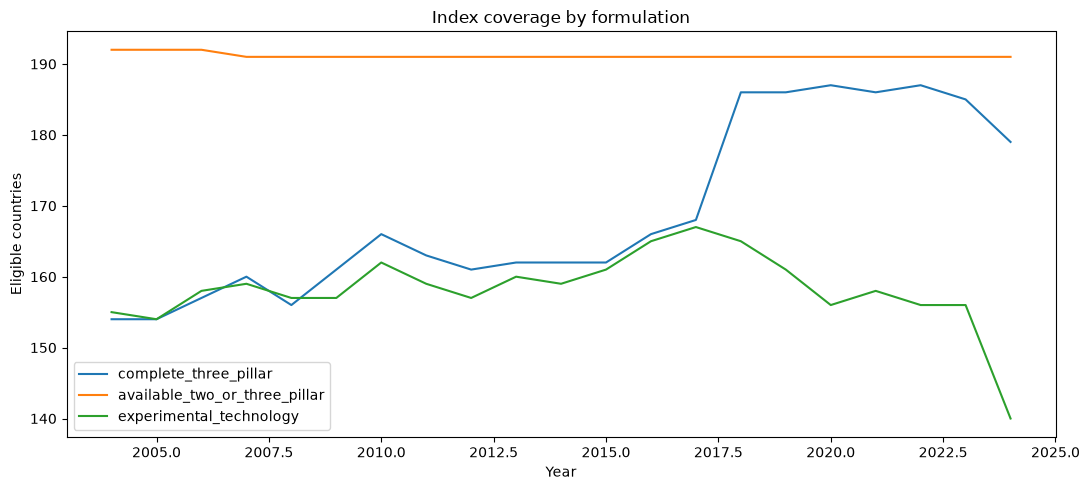

In [5]:
ax = coverage.plot(
    x="year",
    y=["complete_three_pillar", "available_two_or_three_pillar", "experimental_technology"],
    figsize=(11, 5),
)
ax.set(title="Index coverage by formulation", xlabel="Year", ylabel="Eligible countries")
plt.tight_layout()
plt.show()


## 5. Experimental technology impact

The comparison below quantifies how much the former equal-weight four-pillar formulation changes the official three-pillar core. A large systematic shift or many sign reversals supports retaining ICT-goods trade as experimental rather than baseline.


In [6]:
paired = panel.dropna(subset=["core_index_available", "experimental_technology_index"]).copy()
paired["technology_effect"] = paired["experimental_technology_index"] - paired["core_index_available"]
paired["direction_reversal"] = np.sign(paired["experimental_technology_index"]).ne(np.sign(paired["core_index_available"]))
technology_impact = pd.Series({
    "paired_country_years": len(paired),
    "pearson_correlation": paired[["core_index_available", "experimental_technology_index"]].corr().iloc[0, 1],
    "spearman_correlation": paired[["core_index_available", "experimental_technology_index"]].corr(method="spearman").iloc[0, 1],
    "mean_change": paired["technology_effect"].mean(),
    "median_change": paired["technology_effect"].median(),
    "mean_absolute_change": paired["technology_effect"].abs().mean(),
    "direction_reversals": int(paired["direction_reversal"].sum()),
    "direction_reversal_pct": 100 * paired["direction_reversal"].mean(),
})
technology_impact


paired_country_years      3322.000000
pearson_correlation          0.836379
spearman_correlation         0.841407
mean_change                 -0.096304
median_change               -0.136719
mean_absolute_change         0.152201
direction_reversals        852.000000
direction_reversal_pct      25.647200
dtype: float64

In [7]:
named = ["AUS", "IND", "IRN", "JPN", "KOR", "PRK", "RUS", "VNM"]
panel.loc[
    panel["year"].eq(2024) & panel["country_iso3"].isin(named),
    ["country_iso3", "preferred_country_name", *CORE_PILLARS, "technology_score",
     "core_index_available", "experimental_technology_index", "core_index_status"],
].sort_values("country_iso3")


,country_iso3,preferred_country_name,security_score,diplomatic_score,economic_score,technology_score,core_index_available,experimental_technology_index,core_index_status
188,AUS,Australia,0.904147,0.055208,-0.370890,-0.571819,0.196155,0.004162,complete_three_pillar
1616,IND,India,0.211006,-0.344792,-0.075231,-0.897182,-0.069672,-0.276550,complete_three_pillar
1658,IRN,Iran,-0.166667,-0.881944,NaN,NaN,-0.524306,NaN,available_two_pillar_renormalised
1805,JPN,Japan,0.982355,0.026667,-0.031070,-0.711021,0.325984,0.066733,complete_three_pillar
1952,KOR,South Korea,0.930929,0.120000,-0.253931,-0.728087,0.265666,0.017228,complete_three_pillar
2960,PRK,North Korea,-1.000000,-0.876712,-0.418361,NaN,-0.765025,NaN,complete_three_pillar
3065,RUS,Russia,-0.180921,-0.300000,NaN,NaN,-0.240461,NaN,available_two_pillar_renormalised
3887,VNM,Vietnam,0.073593,-0.308219,-0.415952,NaN,-0.216859,NaN,complete_three_pillar


## 6. Security no-ties sensitivity

`security_score = 0` is retained in the baseline because neither anchor has a measured security advantage. The sensitivity below treats rows with zero institutional orientation and zero or unavailable arms-transfer orientation as unavailable comparative security evidence. This tests whether the zero treatment changes direction or only magnitude.


In [8]:
no_ties = panel.loc[panel["security_no_ties_flag"]].copy()
no_ties["absolute_difference"] = no_ties["security_zero_treatment_difference"].abs()
no_ties["direction_reversal"] = (
    np.sign(no_ties["core_index_available"]).ne(
        np.sign(no_ties["core_index_security_no_ties_unavailable"])
    )
    & no_ties["core_index_security_no_ties_unavailable"].notna()
)
security_sensitivity = pd.Series({
    "security_no_ties_country_years": len(no_ties),
    "sensitivity_scores_available": int(no_ties["core_index_security_no_ties_unavailable"].notna().sum()),
    "scores_lost": int(no_ties["core_index_security_no_ties_unavailable"].isna().sum()),
    "mean_absolute_change": no_ties["absolute_difference"].mean(),
    "median_absolute_change": no_ties["absolute_difference"].median(),
    "direction_reversals": int(no_ties["direction_reversal"].sum()),
})
security_sensitivity


security_no_ties_country_years    1474.00000
sensitivity_scores_available      1189.00000
scores_lost                        285.00000
mean_absolute_change                 0.07533
median_absolute_change               0.07011
direction_reversals                  0.00000
dtype: float64

In [9]:
no_ties.sort_values("absolute_difference", ascending=False)[
    ["country_iso3", "preferred_country_name", "year", "security_score",
     "diplomatic_score", "economic_score", "core_index_available",
     "core_index_security_no_ties_unavailable", "absolute_difference"]
].head(25)


,country_iso3,preferred_country_name,year,security_score,diplomatic_score,economic_score,core_index_available,core_index_security_no_ties_unavailable,absolute_difference
1654,IRN,Iran,2020,0.0,-0.917647,-0.709252,-0.542300,-0.813450,0.271150
1655,IRN,Iran,2021,0.0,-0.909091,-0.706097,-0.538396,-0.807594,0.269198
1656,IRN,Iran,2022,0.0,-0.902778,-0.622695,-0.508491,-0.762736,0.254245
1379,GNB,Guinea-Bissau,2018,0.0,-0.878049,-0.484008,-0.454019,-0.681028,0.227009
2885,PLW,Palau,2012,0.0,0.849057,0.473866,0.440974,0.661461,0.220487
2884,PLW,Palau,2011,0.0,0.858491,0.457983,0.438825,0.658237,0.219412
2883,PLW,Palau,2010,0.0,0.845455,0.465992,0.437149,0.655723,0.218574
842,CUB,Cuba,2006,0.0,-0.915522,-0.378297,-0.431273,-0.646909,0.215636
1378,GNB,Guinea-Bissau,2017,0.0,-0.815789,-0.470355,-0.428715,-0.643072,0.214357
1377,GNB,Guinea-Bissau,2016,0.0,-0.830769,-0.448244,-0.426338,-0.639506,0.213169


## 7. Provisional methodological verdict

The baseline retains security no-ties observations at zero because the sensitivity changes magnitude but not direction in the current panel, while treating them as unavailable removes scores for some country-years. The explicit `security_no_ties_flag` must remain visible so that zero is not misread as equally strong ties.

Technology remains experimental because it materially changes the core distribution and is limited to ICT-goods trade orientation rather than a complete measure of technological capability or origin-specific value added.


## 8. Export dashboard-ready data

In [10]:
if WRITE_OUTPUTS:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    panel.to_csv(OUTPUT_DIR / "us_china_relative_orientation_index_country_year.csv", index=False)
    coverage.to_csv(OUTPUT_DIR / "core_index_coverage_by_year.csv", index=False)
    metadata = {
        "period": [2004, 2024],
        "sign_convention": "positive_US_negative_China",
        "official_core_pillars": CORE_PILLARS,
        "official_complete_field": "core_index_complete",
        "official_available_field": "core_index_available",
        "experimental_technology_field": "experimental_technology_index",
        "minimum_core_pillars": 2,
        "technology_role": "experimental_ICT_goods_trade_orientation",
        "relationship_condition_role": "context_only",
    }
    (OUTPUT_DIR / "closeness_index_metadata.json").write_text(
        json.dumps(metadata, indent=2) + "\n", encoding="utf-8"
    )
    print(f"Wrote outputs to {OUTPUT_DIR}")
else:
    print("WRITE_OUTPUTS is False; no repository artefacts written.")


WRITE_OUTPUTS is False; no repository artefacts written.


## 9. Final validation

In [11]:
assert not panel.duplicated(["country_iso3", "year"]).any()
assert panel["year"].between(2004, 2024).all()
for column in ["core_index_complete", "core_index_available", "experimental_technology_index"]:
    assert panel[column].dropna().between(-1, 1).all()
assert not panel.loc[panel["core_available_pillar_count"].lt(2), "core_index_available"].notna().any()
assert set(panel.loc[panel["core_index_status"].eq("complete_three_pillar"), "core_available_pillar_count"]) == {3}

pd.Series({
    "country_year_rows": len(panel),
    "countries": panel["country_iso3"].nunique(),
    "complete_core_scores": panel["core_index_complete"].notna().sum(),
    "available_core_scores": panel["core_index_available"].notna().sum(),
    "experimental_technology_scores": panel["experimental_technology_index"].notna().sum(),
    "security_no_ties_rows": panel["security_no_ties_flag"].sum(),
})


country_year_rows                 4014
countries                          192
complete_core_scores              3548
available_core_scores             4014
experimental_technology_scores    3322
security_no_ties_rows             1474
dtype: int64